In [12]:
with open('saved_models/model.pkl','wb') as f:
    pickle.dump(clf,f)

In [ ]:
"""ToDo: Pre-processing

Z-score transformation within season
Feature specific imputation methods
Model runs scored, runs allowed, aggregate to wins
"""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle
import yaml

import sys
sys.path.append('..')

import xgboost as xgb
import seaborn as sns
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

from utils.ml_utils import plot_calibration_curve, ModelQC
from utils.utils import pg_engine

from sklearn.model_selection import train_test_split

import os
os.environ['DB_HOST'] = 'localhost'

engine = pg_engine()

query = """SELECT * FROM crm_mart.modeling_frame WHERE season not in (2020, 2021)
AND season > 2008
"""
modeling_frame = pd.read_sql(query, con = engine )

""" 
Placeholder model with lots to do

ToDo: Train/Validation/Test Split and/or K-fold CV
ToDo: Model QC
ToDo: Define parameters, features in config
ToDo: Enable Feature Transformations
"""

with open('../modeling/modeling_config.yml', "r") as file:
        ml_config = yaml.safe_load(file)

modeling_frame['home_pitcher_era_season'] = np.where(modeling_frame['home_pitcher_era_season'].isna(), 
                                                     modeling_frame['home_pitcher_era_previous_season'], 
                                                     modeling_frame['home_pitcher_era_season'])

modeling_frame['home_pitcher_era_season'] = np.where(modeling_frame['home_pitcher_era_season'].isna(), 
                                                     modeling_frame['home_pitcher_era_career'], 
                                                     modeling_frame['home_pitcher_era_season'])

modeling_frame['away_pitcher_era_season'] = np.where(modeling_frame['away_pitcher_era_season'].isna(), 
                                                     modeling_frame['away_pitcher_era_previous_season'], 
                                                     modeling_frame['away_pitcher_era_season'])

modeling_frame['away_pitcher_era_season'] = np.where(modeling_frame['away_pitcher_era_season'].isna(), 
                                                     modeling_frame['away_pitcher_era_career'], 
                                                     modeling_frame['away_pitcher_era_season'])

features = ml_config['features']  

X = modeling_frame[features].fillna(-1000)
y = modeling_frame['home_win']

X = modeling_frame[features]

metadata = modeling_frame[['season', 'gamepk', 'gamedate']]

#ToDo: Fill should occur within train and test separately 
# ToDo: Modify to allow non-training feature metadata to be 
# assigned to train-test-split
X_train, X_test, y_train, y_test, metadata_train, metadata_test = train_test_split(X, y, metadata, random_state=412)

dmatrix = xgb.DMatrix(X_train.to_numpy(),y_train.to_numpy())

# Convert YAML search space into skopt space
search_space = {
    param: (
        Integer(v["min"], v["max"]) if v["type"] == "int" else
        Real(v["min"], v["max"], prior=v.get("scale", "uniform")) 
    )
    for param, v in ml_config["search_params"].items()
}

opt = BayesSearchCV(
    xgb.XGBClassifier(objective = 'reg:absoluteerror'),
    search_spaces = search_space,
    n_iter=100,
    verbose=0,
    cv = 10,
    scoring = 'neg_mean_absolute_error',
    random_state = 412
)

opt.fit(X_train, y_train)

clf = xgb.XGBClassifier(**opt.best_params_)
# Fit the model, test sets are used for early stopping.
clf.fit(X_train.to_numpy(), y_train.to_numpy())
# Save model into JSON format.

with open('saved_models/model.pkl','wb') as f:
    pickle.dump(clf,f)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=4.578837426023933, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.21123011217384824,
              max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=25, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=144, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

0.583444279113478
0.5738282626571126
0.24174004867092302
Figure(640x480)


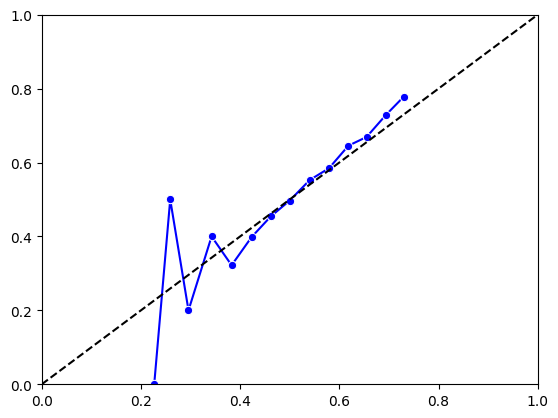

In [4]:
qc_obj2 = ModelQC(clf, X_validation = X_test, y_validation = y_test,
                  X_train = X_train, y_train = y_train,
                   validation_metadata=metadata_test)

print(qc_obj2.train_accuracy)
print(qc_obj2.validation_accuracy)
print(qc_obj2.mse)
print(qc_obj2.calibration_curve)

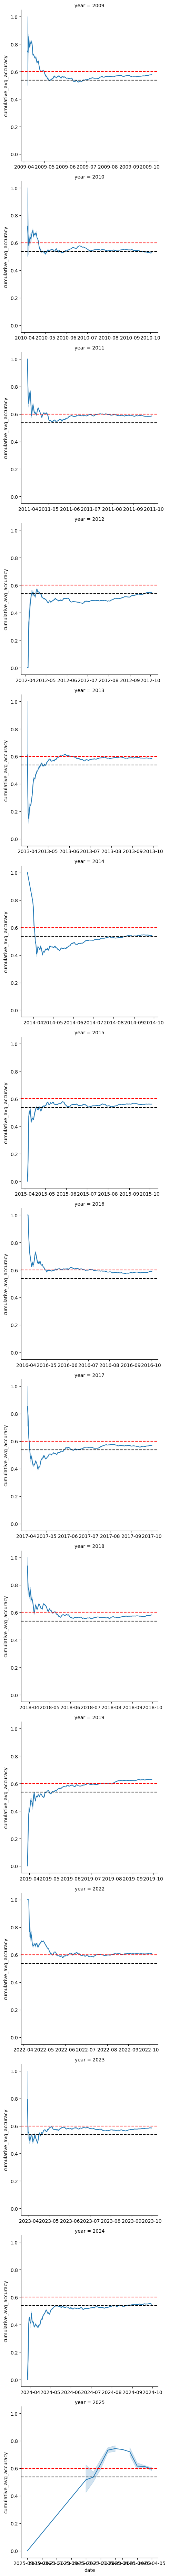

In [5]:
df = qc_obj2.cumulative_accuracy_by_gamedate
df['year'] = df['date'].astype(str).str[:4]

g = sns.relplot(data = df,
             x = 'date',
             y = 'cumulative_avg_accuracy',
             row = 'year',
             kind = 'line', 
             facet_kws={'sharex': False}
 )

# Add a horizontal line at y=0 to each facet
g.refline(y = np.mean(y_test), color = 'black', linestyle = '--')
g.refline(y = 0.6, color = 'red', linestyle = '--')



# Show the plot
plt.show()

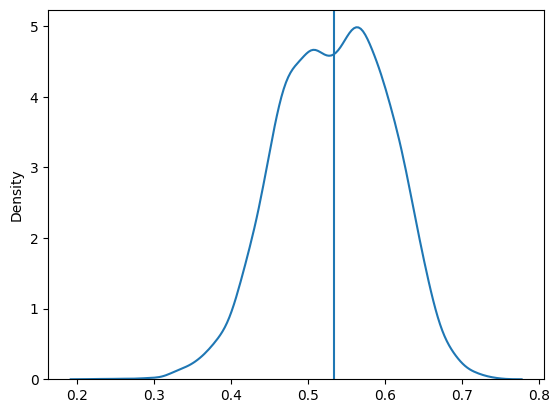

In [11]:
sns.kdeplot(data = qc_obj2.y_val_pred)
plt.axvline(np.mean(qc_obj2.y_val_pred))

In [6]:
df

,date,cumulative_avg_accuracy,year
1533,2009-04-06,1.000000,2009
2708,2009-04-06,0.500000,2009
5766,2009-04-07,0.666667,2009
20503,2009-04-07,0.750000,2009
25443,2009-04-07,0.800000,2009
...,...,...,...
13827,2025-04-05,0.600000,2025
29835,2025-04-05,0.612903,2025
33755,2025-04-05,0.593750,2025
30723,2025-04-05,0.575758,2025
